Projeto M2 - Segmentação e Morfologia
Hugo Bertoglio, Fabricio Prebianca e João Victor Guero
Processamento de Imagens - Professor Felipe Viel - UNIVALI

Neste trabalho usamos K-means para segmentar maçãs, comparamos duas formas de segmentar pele e aplicamos morfologia nas máscaras das maçãs. A ideia é observar na prática o que muda nas imagens quando alteramos os parâmetros de cada método.

Bibliotecas: NumPy para arrays, sorteio e cálculos; Pillow para leitura e redimensionamento; Matplotlib para gráficos; pathlib e collections.deque da biblioteca padrão. A redução para 300 pixels pode remover detalhes finos. Morfologia: Opção 1, aplicada às maçãs.

In [8]:
from pathlib import Path
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


In [9]:
def abrir_imagem(nome):
    imagem = Image.open(Path('imagens') / nome).convert('RGB')
    imagem.thumbnail((300, 300))
    return np.array(imagem)


def mostrar(imagens, titulos):
    fig, eixos = plt.subplots(1, len(imagens), figsize=(4*len(imagens), 4))
    for eixo, imagem, titulo in zip(np.atleast_1d(eixos), imagens, titulos):
        eixo.imshow(imagem, cmap='gray')
        eixo.set_title(titulo)
        eixo.axis('off')
    plt.tight_layout()
    plt.show()




1. Imagens
Usamos as imagens do GitHub da disciplina. Para diminuir o tempo de execução, reduzimos o maior lado para 300 pixels, mantendo a proporção. As comparações usam sempre a mesma versão da imagem.

Os arquivos colors.jpg e variableObjects.jpeg são exemplos extras do diretório e aparecem ao final.

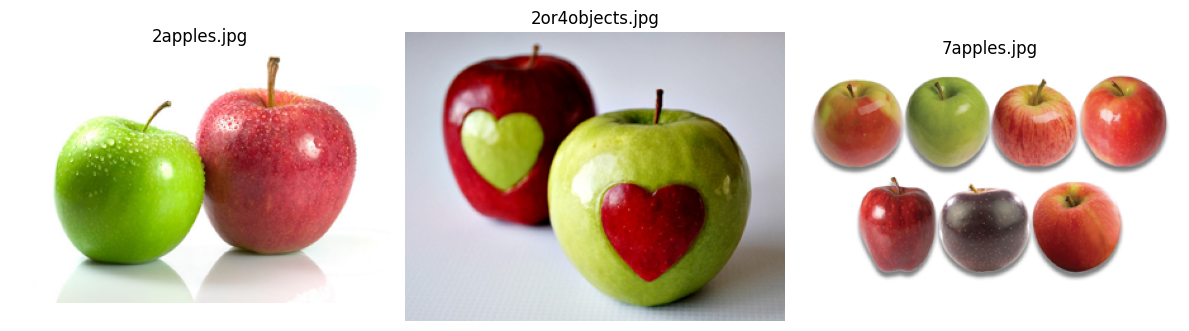

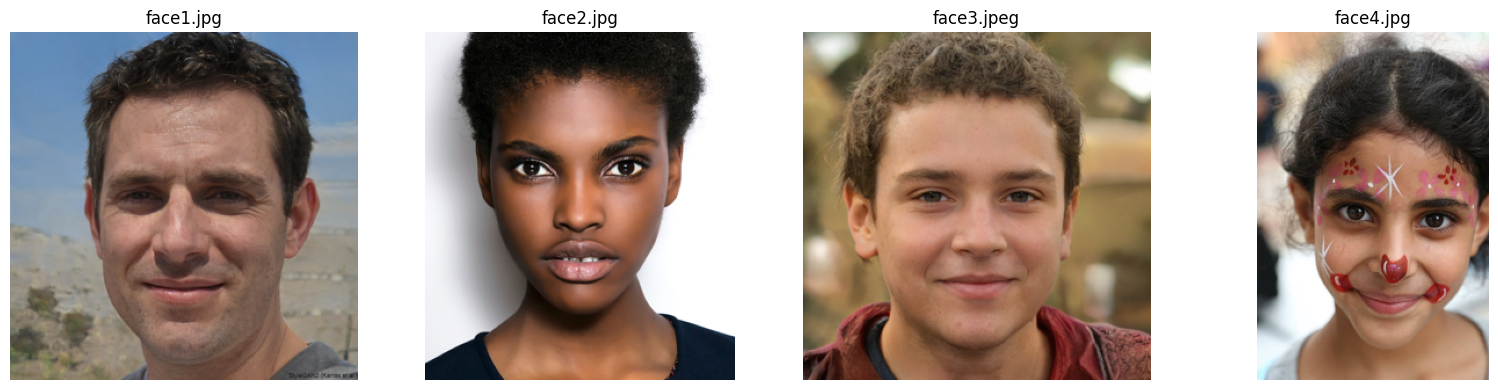

In [10]:
nomes_macas = ['2apples.jpg', '2or4objects.jpg', '7apples.jpg']
nomes_rostos = ['face1.jpg', 'face2.jpg', 'face3.jpeg', 'face4.jpg']
mostrar([abrir_imagem(n) for n in nomes_macas], nomes_macas)
mostrar([abrir_imagem(n) for n in nomes_rostos], nomes_rostos)

2. K-means em RGB e RGB+XY

No RGB, cada pixel é representado por três valores de cor. Em RGB+XY, acrescentamos sua posição. Dividimos as cores por 255 e normalizamos X e Y para ficarem entre 0 e 1. O peso de XY controla quanto a posição influencia a distância.

Usamos a mesma semente aleatória para poder repetir os resultados. O algoritmo sorteia os centros, atribui cada pixel ao centro mais próximo e recalcula os centros pela média. Ele para quando a mudança fica pequena ou quando chega a 100 iterações.

Relação com o exemplo de aula
O exemplo kmeans_segmentation de Prática - Algoritmos de Segmentação usa a mesma sequência de sorteio de centros, atribuição ao centro mais próximo e atualização pelas médias. Aqui normalizamos as cores, acrescentamos XY quando solicitado e calculamos distâncias ao quadrado, que mantêm o mesmo centro mais próximo sem precisar da raiz quadrada. A tolerância de parada de 0,0001 é aplicada à escala normalizada, portanto não equivale à mesma tolerância na escala 0–255.

Há duas outras adaptações: se um grupo fica vazio, mantemos seu centro anterior (o exemplo sorteia outro pixel); ao terminar, recalculamos os rótulos usando os centros finais. Grupos vazios podem fazer as duas versões seguirem caminhos diferentes. Manter o centro é uma escolha simples, mas não garante que todos os K grupos estarão ocupados em qualquer imagem. Por isso, é necessário inspecionar os grupos antes de selecionar as maçãs. RGB+XY continua sendo K-means em cinco dimensões;


In [11]:
def calcular_distancias(dados, centros):
    k = len(centros)
    distancias = np.zeros((len(dados), k))
    for i in range(k):
        diferenca = dados - centros[i]
        distancias[:, i] = np.sum(diferenca ** 2, axis=1)
    return distancias


def kmeans(imagem, k, usar_xy=False, peso_xy=0.3):
    altura, largura = imagem.shape[:2]
    cores = imagem.reshape(-1, 3).astype(float) / 255
    dados = cores

    if usar_xy:
        y, x = np.indices((altura, largura))
        x = x.ravel() / max(largura - 1, 1)
        y = y.ravel() / max(altura - 1, 1)
        dados = np.column_stack((cores, peso_xy * x, peso_xy * y))

    sorteio = np.random.default_rng(42)
    indices = sorteio.choice(len(dados), k, replace=False)
    centros = dados[indices].copy()

    for _ in range(100):
        distancias = calcular_distancias(dados, centros)
        grupos = distancias.argmin(axis=1)
        novos_centros = centros.copy()

        for grupo in range(k):
            pixels = dados[grupos == grupo]
            if len(pixels) > 0:
                novos_centros[grupo] = pixels.mean(axis=0)

        mudou = np.linalg.norm(novos_centros - centros)
        centros = novos_centros
        if mudou < 0.0001:
            break

    distancias = calcular_distancias(dados, centros)
    grupos = distancias.argmin(axis=1).reshape(altura, largura)
    reconstruida = (centros[grupos, :3] * 255).clip(0, 255).astype(np.uint8)
    return grupos, reconstruida, centros


def ver_grupos(imagem, grupos, k):
    colunas = (k + 1) // 2
    fig, eixos = plt.subplots(2, colunas, figsize=(3 * colunas, 6), squeeze=False)
    for grupo, eixo in enumerate(eixos.ravel()):
        if grupo < k:
            eixo.imshow(grupos == grupo, cmap='gray')
            eixo.set_title(f'Grupo {grupo}')
        eixo.axis('off')
    plt.tight_layout()
    plt.show()


Escolha de K

Para as imagens com duas maçãs, começamos com K=4 para representar as cores das frutas e as diferenças entre fundo e reflexos. Para a imagem com sete maçãs, usamos K=8 como ponto de partida, incluindo o fundo. Isso não significa que cada maçã terá um grupo próprio.

O peso principal de XY é 0,3. Mais adiante, comparamos outros valores para ver seu efeito.

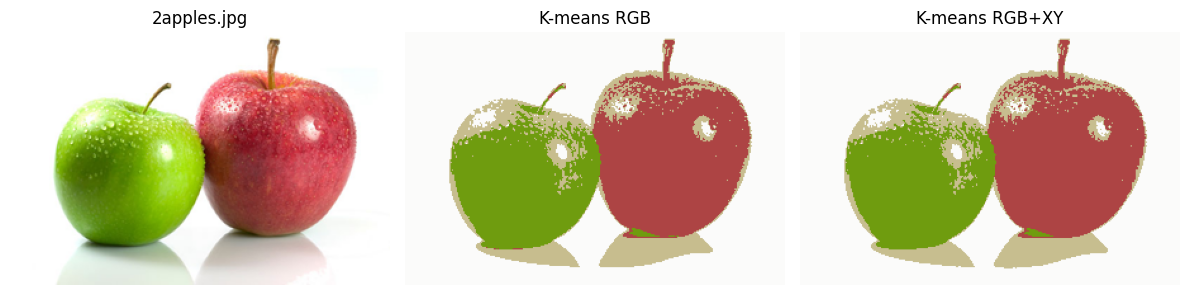

Centros RGB: [[174  69  68]
 [199 190 142]
 [251 252 250]
 [112 157  16]]
Centros RGB+XY: [[174  69  68]
 [251 252 250]
 [199 191 143]
 [112 157  16]]


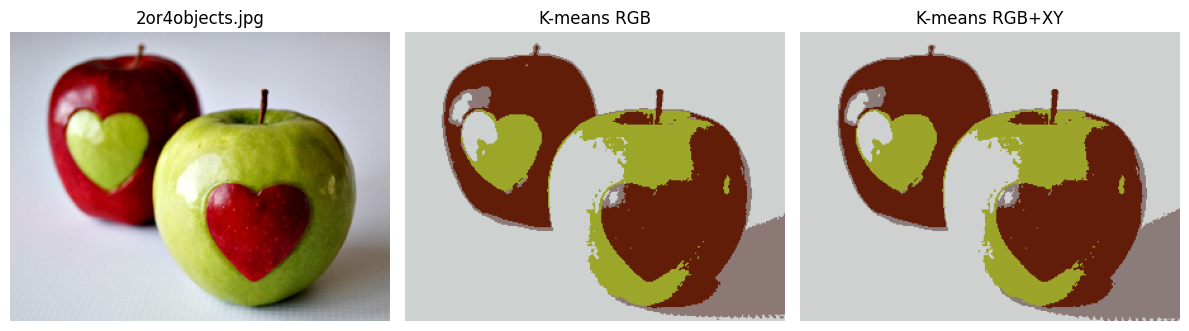

Centros RGB: [[206 209 208]
 [ 98  29   9]
 [140 121 117]
 [156 166  41]]
Centros RGB+XY: [[206 209 209]
 [ 98  29   9]
 [140 124 121]
 [156 166  42]]


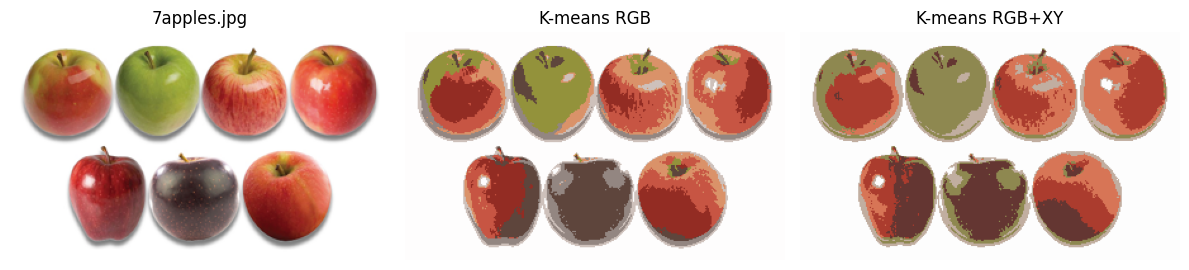

Centros RGB: [[218 146 105]
 [ 94  69  61]
 [148 146  60]
 [199  85  67]
 [148 134 129]
 [207 194 187]
 [254 254 254]
 [147  44  35]]
Centros RGB+XY: [[254 253 253]
 [101  54  50]
 [143 136  81]
 [215 118  87]
 [194 175 160]
 [253 253 253]
 [253 253 253]
 [172  60  46]]


In [12]:
valores_k = [4, 4, 8]
resultados = {}
for nome, k in zip(nomes_macas, valores_k):
    imagem = abrir_imagem(nome)
    grupos_rgb, imagem_rgb, centros_rgb = kmeans(imagem, k)
    grupos_xy, imagem_xy, centros_xy = kmeans(imagem, k, usar_xy=True)
    resultados[nome] = {'imagem': imagem, 'rgb': grupos_rgb, 'xy': grupos_xy}
    mostrar([imagem, imagem_rgb, imagem_xy], [nome, 'K-means RGB', 'K-means RGB+XY'])
    print('Centros RGB:', np.round(centros_rgb[:,:3]*255).astype(int))
    print('Centros RGB+XY:', np.round(centros_xy[:,:3]*255).astype(int))

Dos grupos para as máscaras

Para escolher os grupos das maçãs, olhamos cada grupo separadamente. Depois juntamos os que representam as frutas. Essa escolha é manual: se trocarmos a imagem, K ou a inicialização, precisamos conferir novamente os grupos.

2apples.jpg - grupos RGB


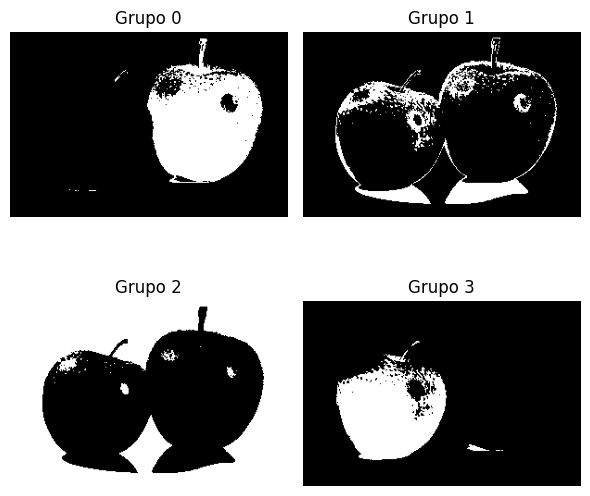

2apples.jpg - grupos RGB+XY


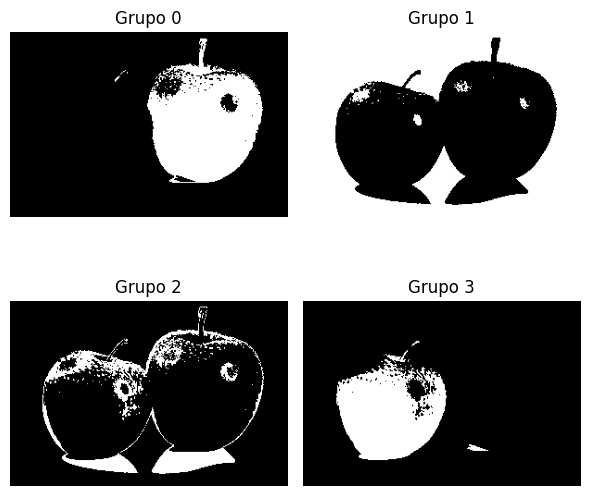

2or4objects.jpg - grupos RGB


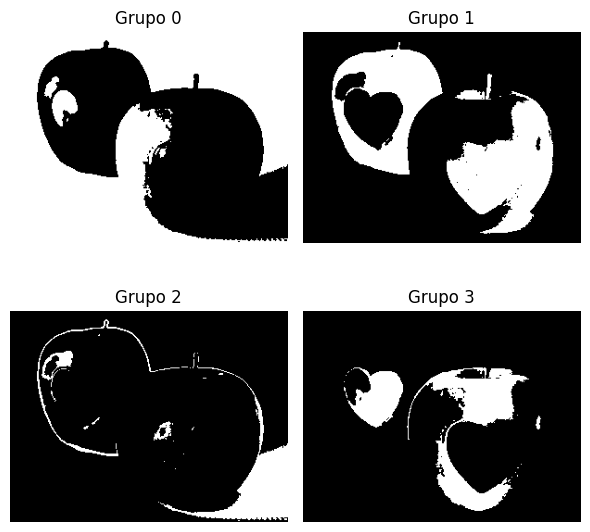

2or4objects.jpg - grupos RGB+XY


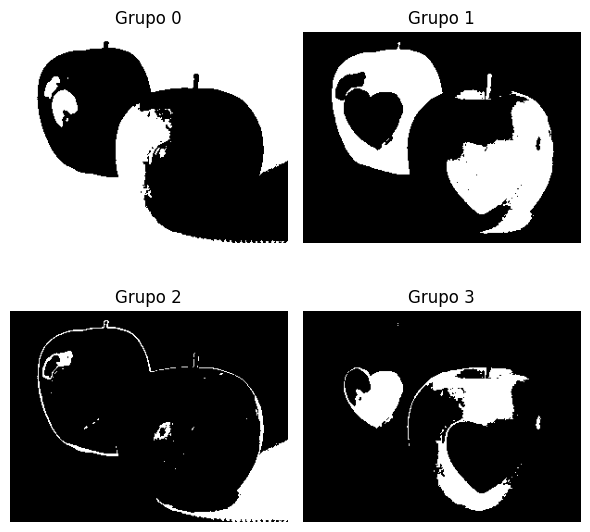

7apples.jpg - grupos RGB


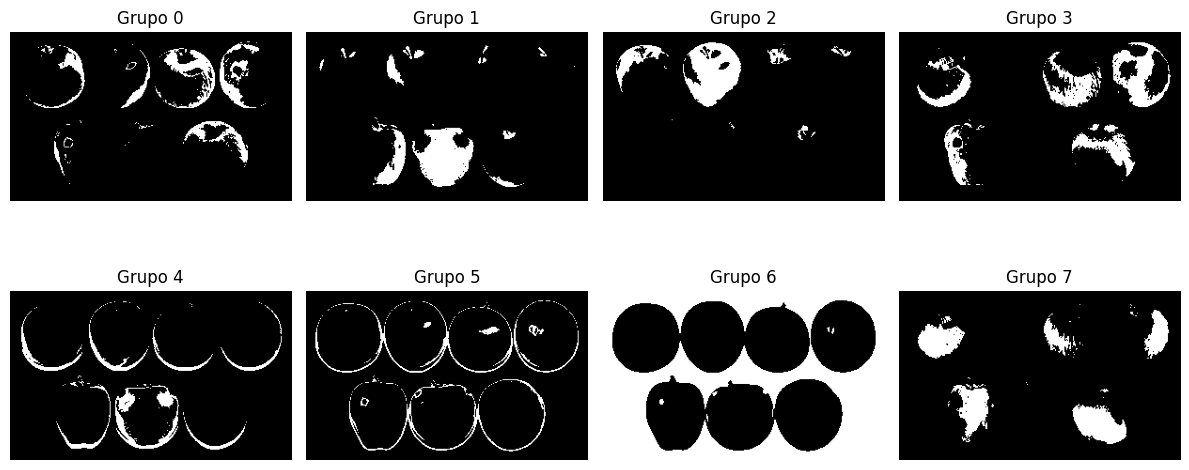

7apples.jpg - grupos RGB+XY


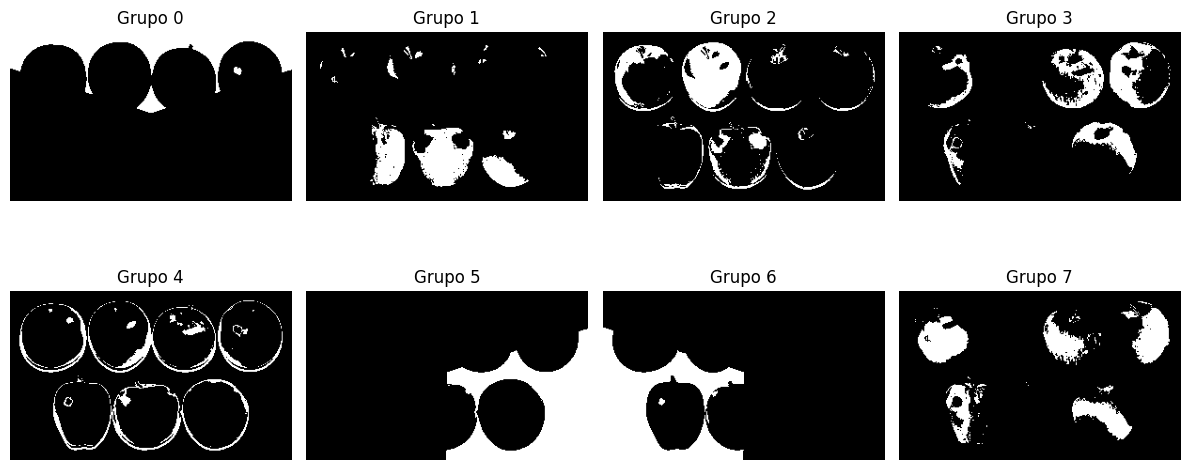

In [13]:
for nome, k in zip(nomes_macas, valores_k):
    print(nome, '- grupos RGB')
    ver_grupos(resultados[nome]['imagem'], resultados[nome]['rgb'], k)
    print(nome, '- grupos RGB+XY')
    ver_grupos(resultados[nome]['imagem'], resultados[nome]['xy'], k)

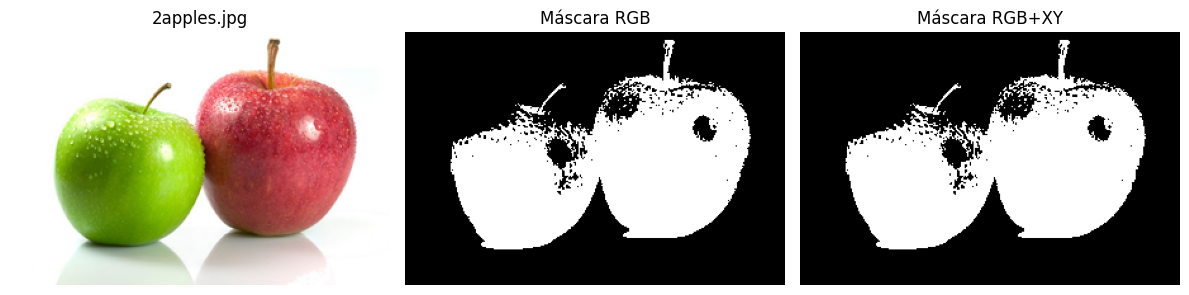

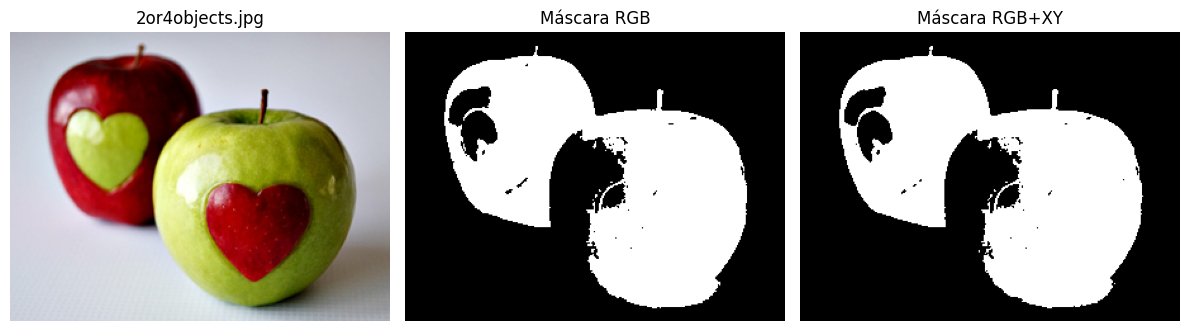

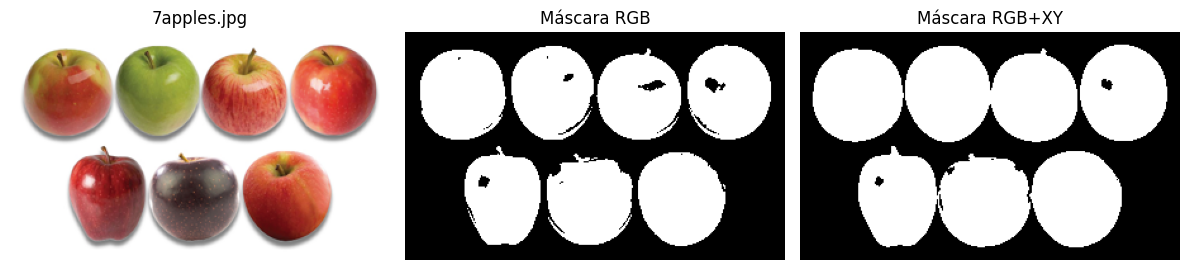

In [14]:
grupos_escolhidos = {
    '2apples.jpg': {'rgb': [0, 3], 'xy': [0, 3]},
    '2or4objects.jpg': {'rgb': [1, 3], 'xy': [1, 3]},
    '7apples.jpg': {'rgb': [0, 1, 2, 3, 4, 7], 'xy': [1, 2, 3, 4, 7]}
}
for nome in nomes_macas:
    for metodo in ['rgb', 'xy']:
        resultados[nome]['mascara_'+metodo] = np.isin(
            resultados[nome][metodo], grupos_escolhidos[nome][metodo])
    mostrar([resultados[nome]['imagem'], resultados[nome]['mascara_rgb'],
             resultados[nome]['mascara_xy']], [nome, 'Máscara RGB', 'Máscara RGB+XY'])

Em 2apples, deixamos de fora o grupo que contém boa parte dos reflexos, mas isso também retira detalhes claros das frutas. Em 2or4objects, o grupo cinza inclui bordas e sombra do fundo. As máscaras mostram que separar cor não é o mesmo que separar perfeitamente cada objeto.

Teste com K e peso espacial

No primeiro teste mudamos apenas K. No segundo, mantemos K=4 e mudamos apenas o peso XY.

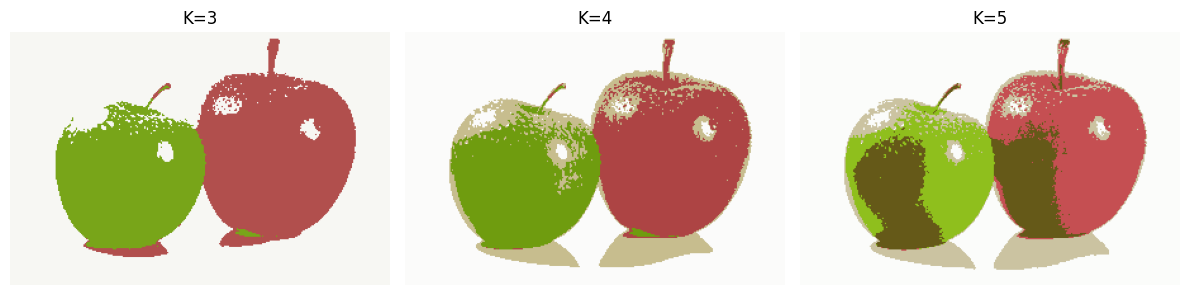

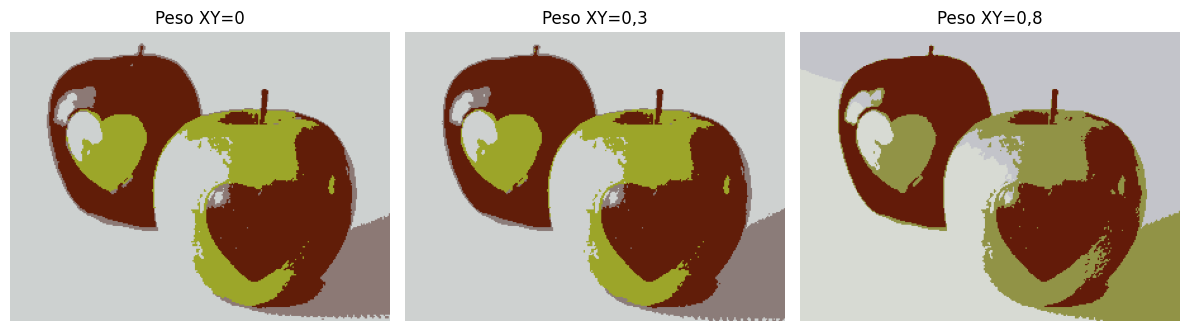

In [15]:
imagem = abrir_imagem('2apples.jpg')
comparacao_k = [kmeans(imagem, k)[1] for k in [3, 4, 5]]
mostrar(comparacao_k, ['K=3', 'K=4', 'K=5'])
imagem = abrir_imagem('2or4objects.jpg')
comparacao_xy = [kmeans(imagem, 4, usar_xy=True, peso_xy=p)[1] for p in [0, 0.3, 0.8]]
mostrar(comparacao_xy, ['Peso XY=0', 'Peso XY=0,3', 'Peso XY=0,8'])

Dispersão 3D RGB

O gráfico é feito somente para 2or4objects.jpg, como solicitado. Os eixos são R, G e B e as cores dos pontos indicam os grupos. Usamos uma amostra de 5 mil pixels para o gráfico não ficar pesado. O K-means continua usando todos os pixels da imagem reduzida.

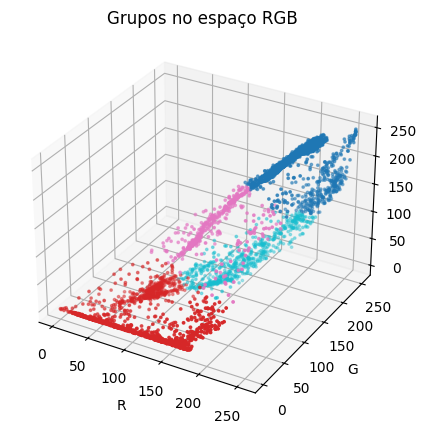

In [16]:
imagem = resultados['2or4objects.jpg']['imagem']
pixels = imagem.reshape(-1,3)
grupos = resultados['2or4objects.jpg']['rgb'].ravel()
amostra = np.random.default_rng(42).choice(len(pixels), min(5000,len(pixels)), replace=False)
fig = plt.figure(figsize=(7,5))
eixo = fig.add_subplot(111, projection='3d')
eixo.scatter(*pixels[amostra].T, c=grupos[amostra], cmap='tab10', s=3)
eixo.set(xlabel='R', ylabel='G', zlabel='B', title='Grupos no espaço RGB')
plt.show()

3. Morfologia nas maçãs

Implementamos erosão e dilatação. A abertura faz erosão e depois dilatação; o fechamento faz o contrário. Usamos um elemento quadrado. Fora da imagem, consideramos fundo.

Primeiro, aplicamos cada operação separadamente para enxergar seu efeito. Depois testamos abertura seguida de fechamento nas duas máscaras.


In [17]:
def erosao(mascara, tamanho=3):
    borda = tamanho // 2
    imagem_pad = np.pad(mascara, borda, constant_values=False)
    altura, largura = mascara.shape
    resultado = np.zeros((altura, largura), dtype=bool)

    for y in range(altura):
        for x in range(largura):
            vizinhanca = imagem_pad[y:y + tamanho, x:x + tamanho]
            if np.all(vizinhanca):
                resultado[y, x] = True
    return resultado


def dilatacao(mascara, tamanho=3):
    borda = tamanho // 2
    imagem_pad = np.pad(mascara, borda, constant_values=False)
    altura, largura = mascara.shape
    resultado = np.zeros((altura, largura), dtype=bool)

    for y in range(altura):
        for x in range(largura):
            vizinhanca = imagem_pad[y:y + tamanho, x:x + tamanho]
            if np.any(vizinhanca):
                resultado[y, x] = True
    return resultado


def abertura(mascara, tamanho=3):
    return dilatacao(erosao(mascara, tamanho), tamanho)


def fechamento(mascara, tamanho=3):
    return erosao(dilatacao(mascara, tamanho), tamanho)


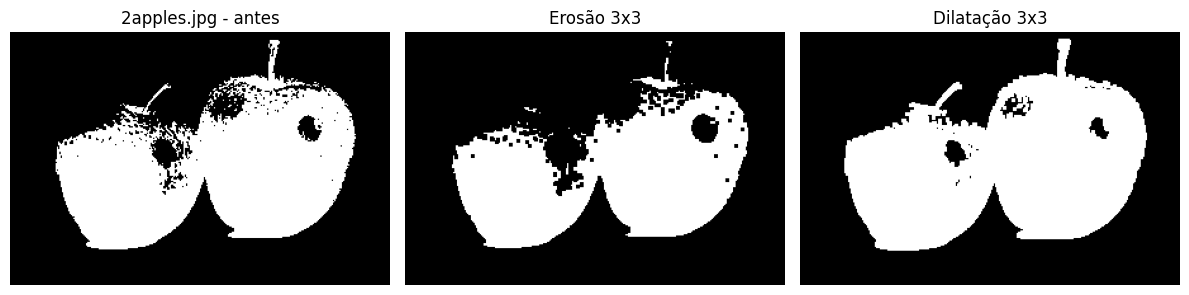

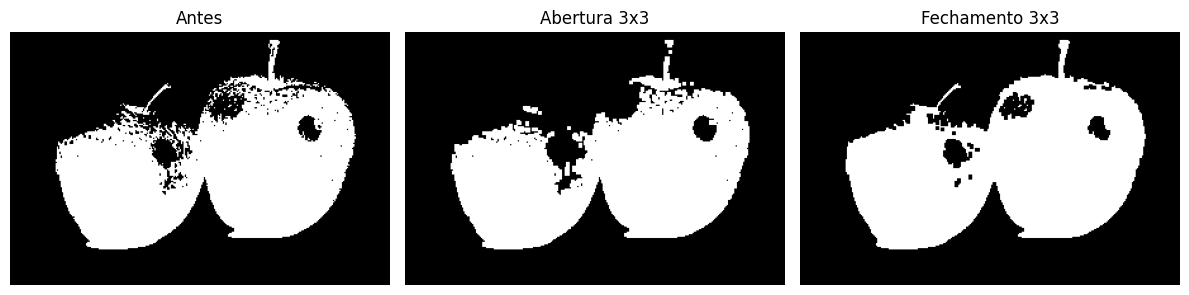

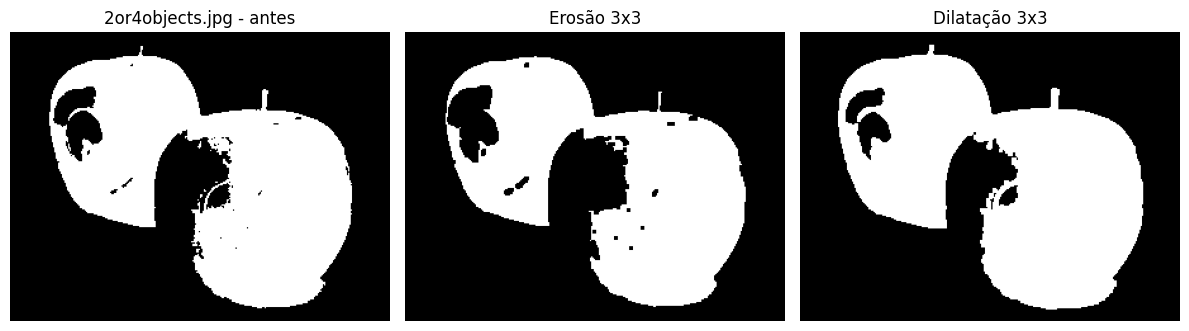

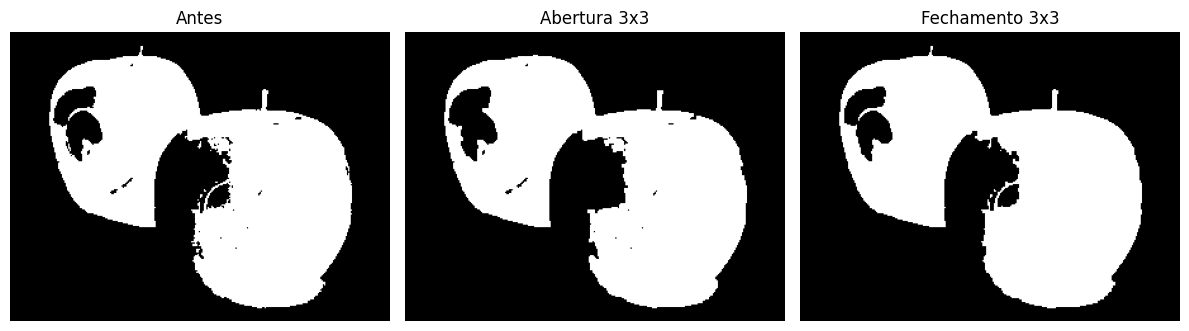

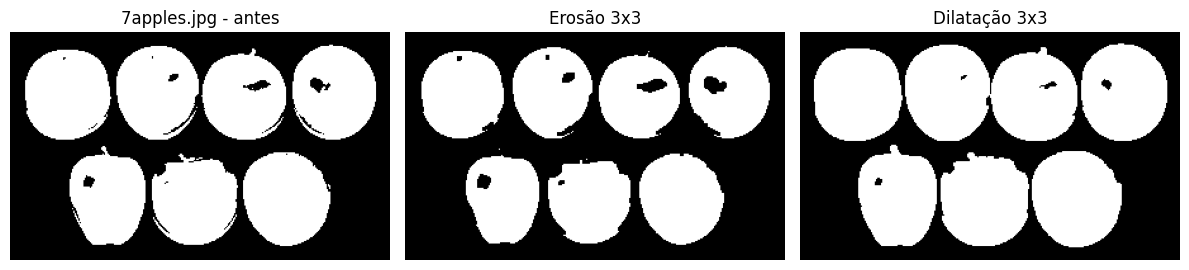

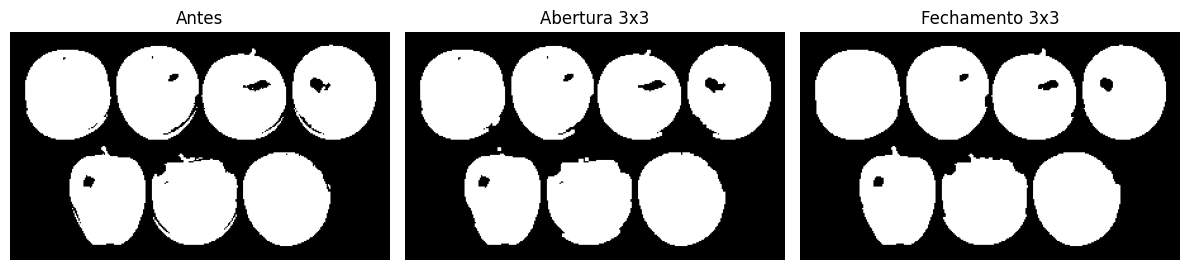

In [18]:
for nome in nomes_macas:
    mascara = resultados[nome]['mascara_rgb']
    mostrar([mascara, erosao(mascara), dilatacao(mascara)],
            [nome+' - antes', 'Erosão 3x3', 'Dilatação 3x3'])
    mostrar([mascara, abertura(mascara), fechamento(mascara)],
            ['Antes', 'Abertura 3x3', 'Fechamento 3x3'])

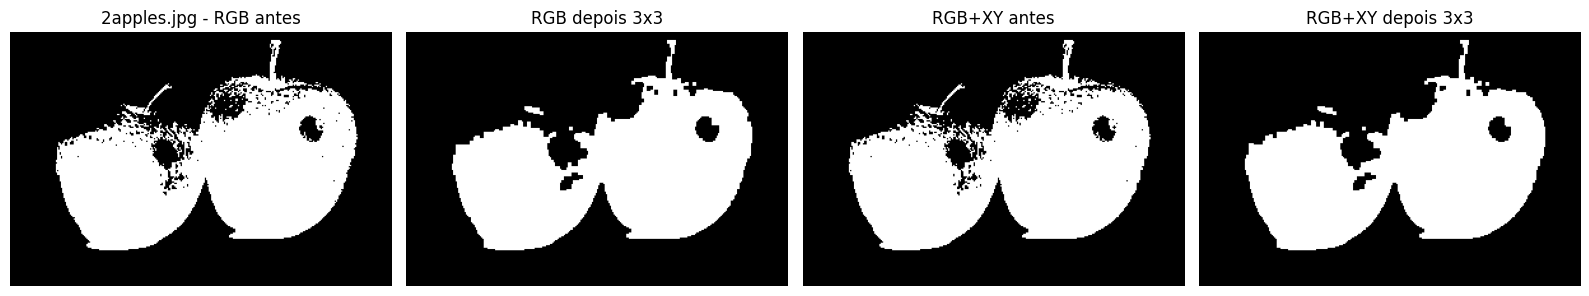

Pixels diferentes entre os métodos: 0.16% antes; 0.18% depois.


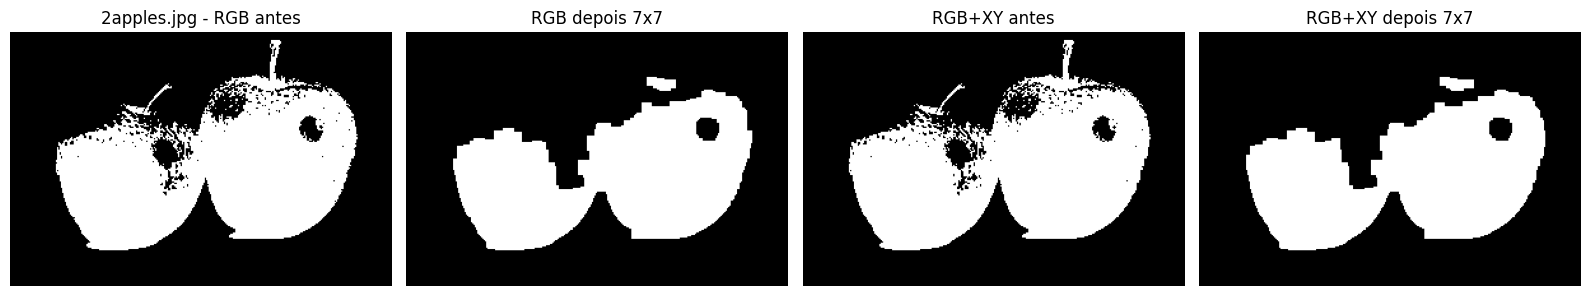

Pixels diferentes entre os métodos: 0.16% antes; 0.27% depois.


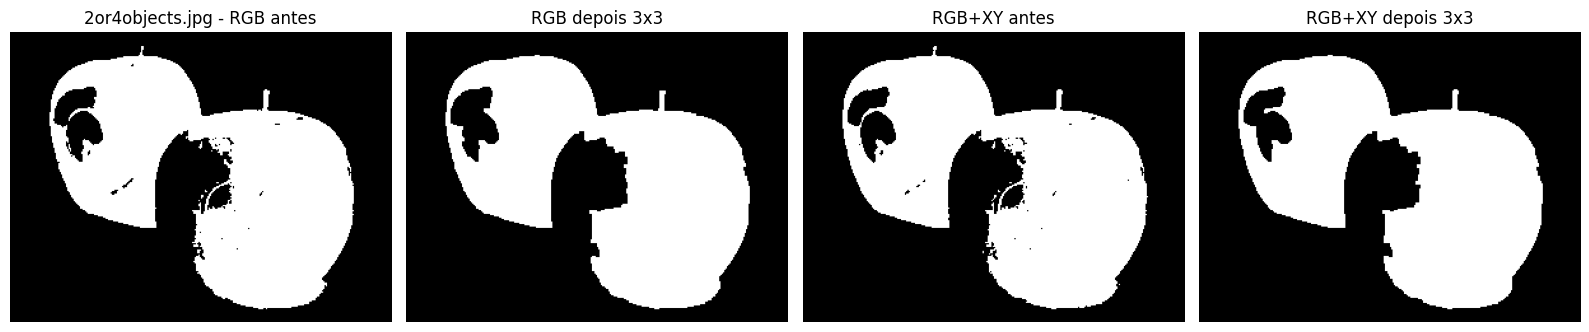

Pixels diferentes entre os métodos: 0.31% antes; 0.31% depois.


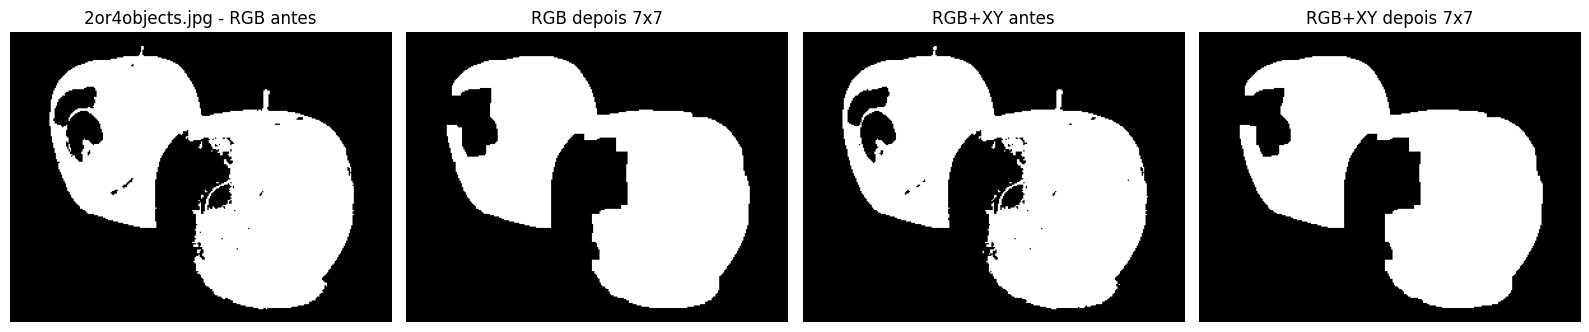

Pixels diferentes entre os métodos: 0.31% antes; 0.24% depois.


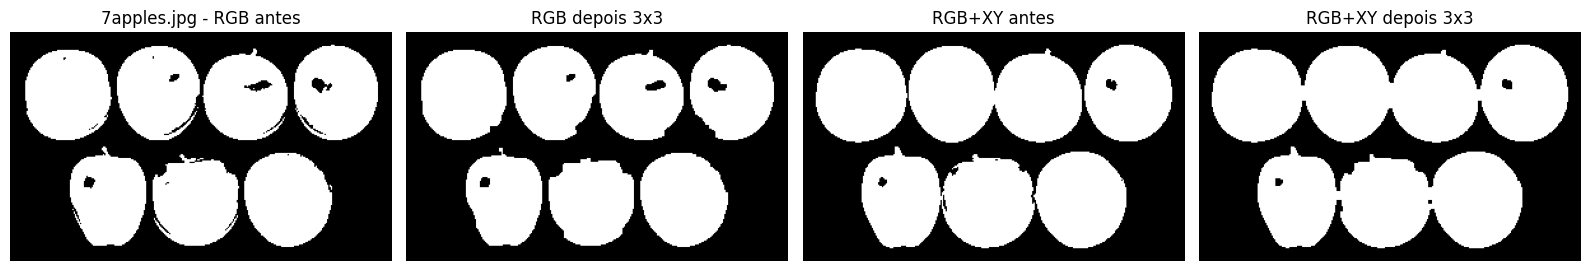

Pixels diferentes entre os métodos: 4.06% antes; 4.53% depois.


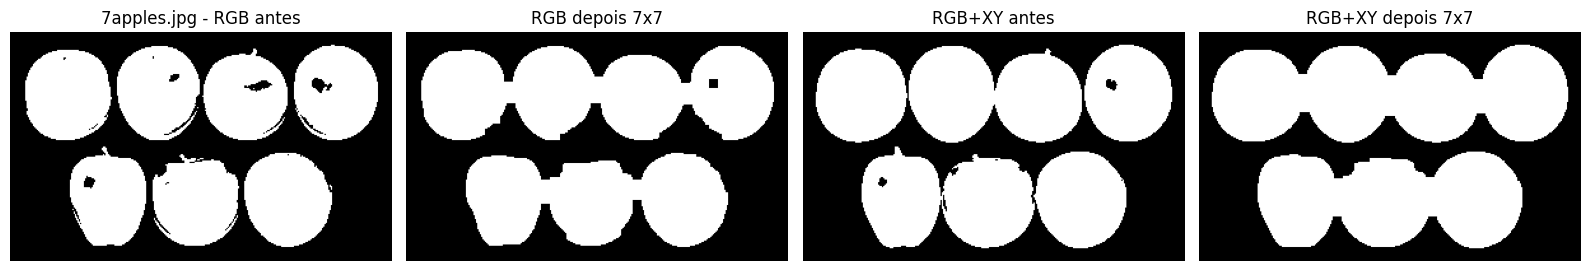

Pixels diferentes entre os métodos: 4.06% antes; 4.44% depois.


In [19]:
comparacoes_morfologia = []
for nome in nomes_macas:
    rgb = resultados[nome]['mascara_rgb']
    xy = resultados[nome]['mascara_xy']
    for tamanho in [3, 7]:
        rgb_depois = fechamento(abertura(rgb, tamanho), tamanho)
        xy_depois = fechamento(abertura(xy, tamanho), tamanho)
        mostrar([rgb, rgb_depois, xy, xy_depois],
                [nome+' - RGB antes', f'RGB depois {tamanho}x{tamanho}',
                 'RGB+XY antes', f'RGB+XY depois {tamanho}x{tamanho}'])
        antes = 100*np.mean(rgb != xy)
        depois = 100*np.mean(rgb_depois != xy_depois)
        comparacoes_morfologia.append((nome, tamanho, antes, depois))
        print(f'Pixels diferentes entre os métodos: {antes:.2f}% antes; {depois:.2f}% depois.')

A abertura remove pequenos pontos e pode apagar detalhes finos. O fechamento corrige falhas pequenas, mas também pode unir partes próximas. O elemento 7x7 altera mais as formas que o 3x3.

A porcentagem de pixels diferentes serve para ver se as duas máscaras ficaram mais parecidas. Uma diferença menor não significa, sozinha, que o resultado ficou correto: é preciso olhar o que mudou nas frutas.

A morfologia não reduz as diferenças de forma consistente: em 2or4objects com 7x7, 0,31% passa a 0,24%; em 7apples, 4,06% passa a 4,44%; em 2apples, 0,16% passa a 0,27%. Em 7apples com 7x7 aparecem pontes entre frutas, prejudicando sua separação.

4. Segmentação de pele em RGB e HSV

Em RGB, usamos as condições R>95, G>40, B>20, R>G, R>B e |R-G|>15. Em HSV, usamos H de 0 a 50 graus e S de 0,23 a 0,68. Esses valores foram retirados do artigo indicado no enunciado, avaliando cada espaço separadamente.

A conversão para HSV e a classificação dos pixels estão implementadas abaixo. O artigo propõe uma combinação de modelos; aqui fazemos a comparação RGB versus HSV pedida no trabalho.

In [20]:
def pele_rgb(imagem):
    r = imagem[:, :, 0].astype(float)
    g = imagem[:, :, 1].astype(float)
    b = imagem[:, :, 2].astype(float)
    return ((r > 95) & (g > 40) & (b > 20) &
            (r > g) & (r > b) & (np.abs(r - g) > 15))


def converter_hsv(imagem):
    rgb = imagem.astype(float) / 255.0
    r = rgb[:, :, 0]
    g = rgb[:, :, 1]
    b = rgb[:, :, 2]

    maior = np.maximum(np.maximum(r, g), b)
    menor = np.minimum(np.minimum(r, g), b)
    diferenca = maior - menor

    h = np.zeros_like(maior)
    s = np.zeros_like(maior)

    for y in range(imagem.shape[0]):
        for x in range(imagem.shape[1]):
            diff = diferenca[y, x]
            cmax = maior[y, x]

            if diff > 0:
                if cmax == r[y, x]:
                    h[y, x] = 60 * (((g[y, x] - b[y, x]) / diff) % 6)
                elif cmax == g[y, x]:
                    h[y, x] = 60 * (((b[y, x] - r[y, x]) / diff) + 2)
                else:
                    h[y, x] = 60 * (((r[y, x] - g[y, x]) / diff) + 4)

            if cmax > 0:
                s[y, x] = diff / cmax

    v = maior
    return h, s, v


def pele_hsv(imagem, saturacao_min=0.23, saturacao_max=0.68):
    h, s, v = converter_hsv(imagem)
    return ((h >= 0) & (h <= 50) &
            (s >= saturacao_min) & (s <= saturacao_max))


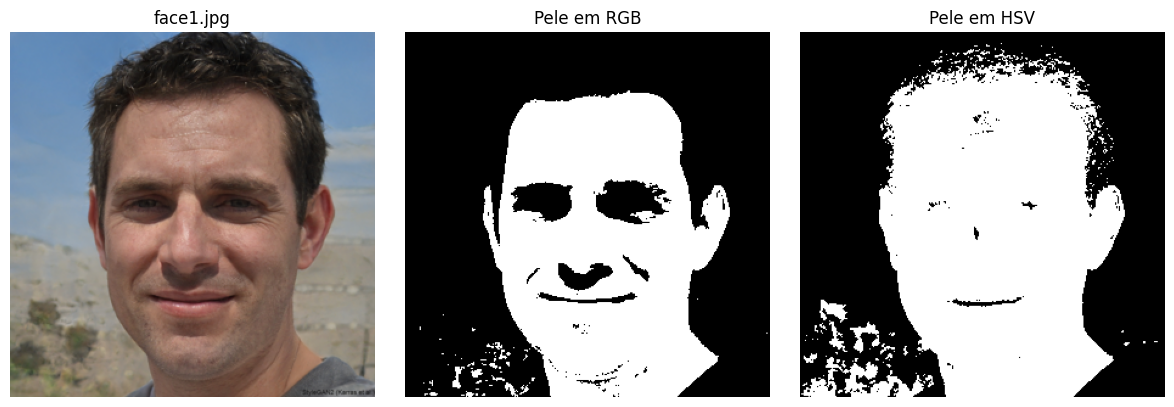

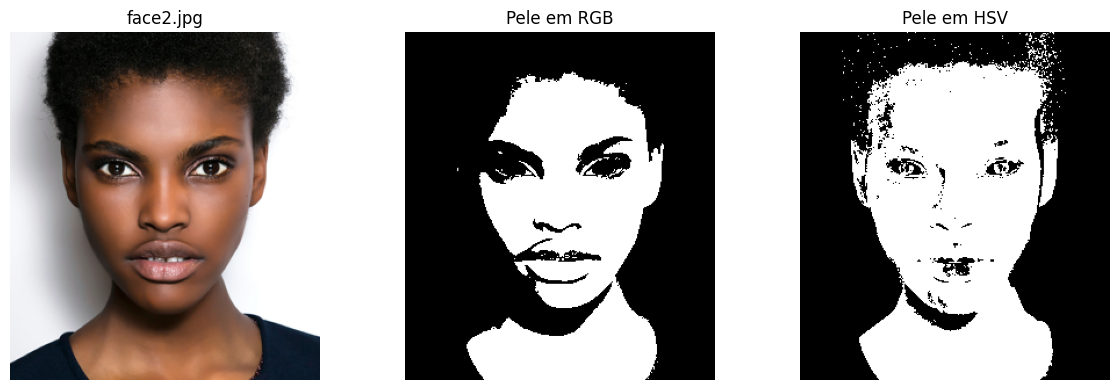

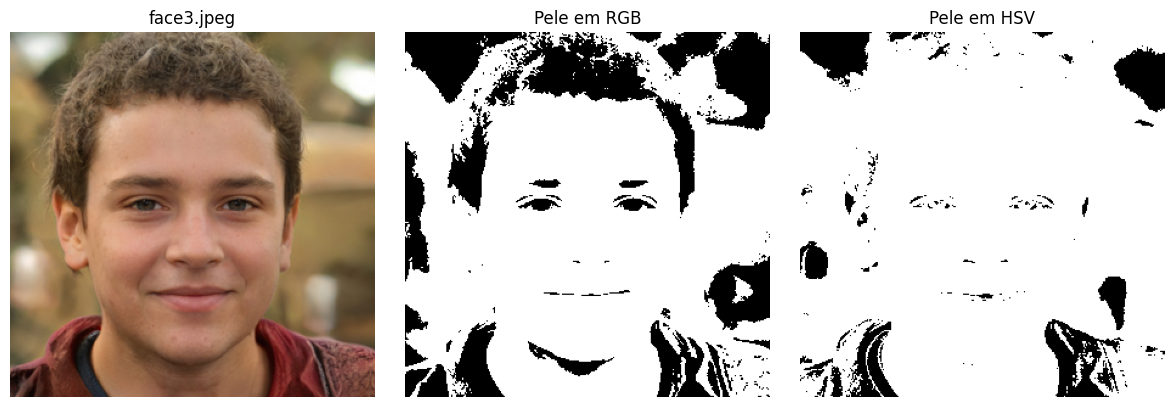

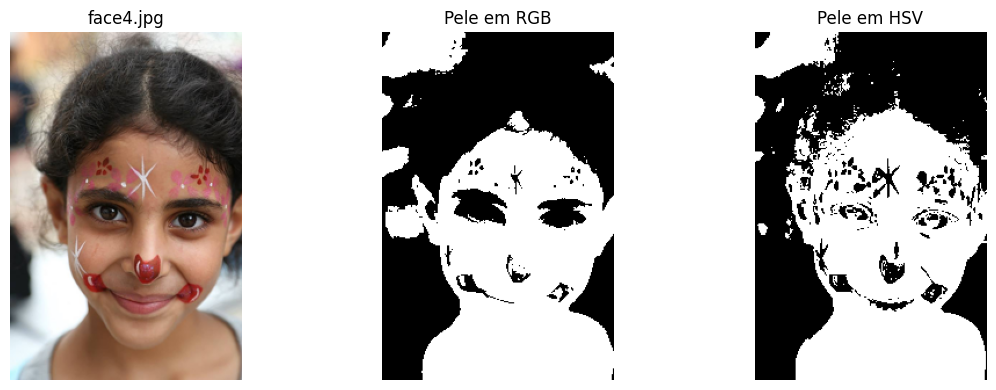

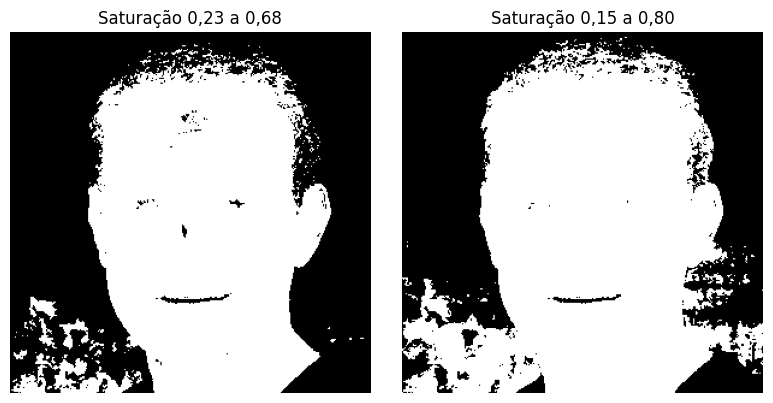

In [21]:
for nome in nomes_rostos:
    imagem = abrir_imagem(nome)
    mostrar([imagem, pele_rgb(imagem), pele_hsv(imagem)],
            [nome, 'Pele em RGB', 'Pele em HSV'])

imagem = abrir_imagem('face1.jpg')
mostrar([pele_hsv(imagem, 0.23, 0.68), pele_hsv(imagem, 0.15, 0.80)],
        ['Saturação 0,23 a 0,68', 'Saturação 0,15 a 0,80'])

In [22]:
# Area marcada, sem interpretacao como acuracia.
for nome in nomes_rostos:
    imagem = abrir_imagem(nome)
    print(f'{nome}: RGB={100*pele_rgb(imagem).mean():.2f}%; HSV={100*pele_hsv(imagem).mean():.2f}%')


face1.jpg: RGB=37.70%; HSV=49.65%
face2.jpg: RGB=34.08%; HSV=45.23%
face3.jpeg: RGB=73.77%; HSV=89.79%
face4.jpg: RGB=50.18%; HSV=52.32%


Análise de RGB e HSV

Em face2.jpg, a máscara HSV cobre mais regiões visíveis da face que a RGB, mas também aceita pontos no cabelo e outras áreas. O HSV separa matiz e saturação do valor V; isso pode ajudar sob variações de intensidade, mas não garante invariância à iluminação. Sem uma máscara de referência e uma análise dos canais por região, não atribuímos cada falha ao corte R > 95 nem afirmamos superioridade geral.

Em face3.jpeg, o RGB marca 73,77% da imagem e o HSV, 89,79%. Visualmente, o HSV inclui mais fundo, mas o RGB também aceita grandes áreas fora da face: nenhum dos dois isola o rosto. As porcentagens medem área marcada, não acurácia. As regras RGB contêm vários testes simultâneos; não foi isolada a contribuição de |R - G| > 15. O fundo desfocado tem cores semelhantes às da pele, sem permitir identificar com segurança seus materiais.

Os métodos segmentam cores compatíveis com pele, incluindo pescoço e outras partes expostas; não reconhecem semanticamente um rosto.

5. Crescimento de regiões

Escolhemos manualmente uma semente na pele. O algoritmo mantém uma fila de pixels que ainda terão seus vizinhos analisados. Para cada vizinho, comparamos a cor com a média da região. Se a distância for menor ou igual à tolerância, ele entra na máscara.

A média é calculada como soma das cores dividida pela quantidade de pixels aceitos. Usamos os quatro vizinhos: acima, abaixo, esquerda e direita. Cada candidato é avaliado uma vez; por isso, a ordem de visita pode influenciar a expansão.

Aqui as cores estão de 0 a 255. Testamos tolerâncias 40, 65 e 90; não são valores de porcentagem.

A média é um vetor RGB, não uma intensidade escalar em tons de cinza. A fila implementa a expansão iterativamente, sem recursão de funções.

Comparação com exercise_3_segmentation_example.py
O professor também usa deque, fila FIFO e média atualizada. Seu exemplo trabalha em tons de cinza, com oito vizinhos e várias sementes, e aceita pixels quando a diferença absoluta é menor que o limiar. Nossa versão usa uma semente por execução, quatro vizinhos e distância Euclidiana à média RGB, aceitando valores menores ou iguais à tolerância. A atualização por soma/quantidade evita guardar e recalcular a média de toda a lista de pixels.

Uma diferença importante é visitados: aqui um candidato rejeitado não volta a ser testado. No exemplo da aula, como só os aceitos recebem rótulo, um rejeitado pode ser testado novamente ao ser alcançado por outro vizinho aceito, com uma média diferente. Portanto, as duas versões não precisam produzir a mesma região. A avaliação única simplifica o processamento, mas pode limitar a expansão; essa limitação deve ser considerada na análise. As tolerâncias RGB 40/65/90 também não equivalem aos limiares 4/8 do exercício em cinza.

In [23]:
def crescer_regiao(imagem, semente, tolerancia):
    imagem = imagem.astype(float)
    altura, largura = imagem.shape[:2]
    mascara = np.zeros((altura, largura), dtype=bool)
    visitados = np.zeros_like(mascara)
    y, x = semente
    mascara[y,x] = True
    visitados[y,x] = True
    fila = deque([(y,x)])
    soma = imagem[y,x].copy()
    quantidade = 1

    while fila:
        y, x = fila.popleft()
        for dy, dx in [(-1,0), (1,0), (0,-1), (0,1)]:
            ny, nx = y+dy, x+dx
            if 0 <= ny < altura and 0 <= nx < largura and not visitados[ny,nx]:
                visitados[ny,nx] = True
                media = soma/quantidade
                distancia = np.linalg.norm(imagem[ny,nx]-media)
                if distancia <= tolerancia:
                    mascara[ny,nx] = True
                    soma += imagem[ny,nx]
                    quantidade += 1
                    fila.append((ny,nx))
    return mascara


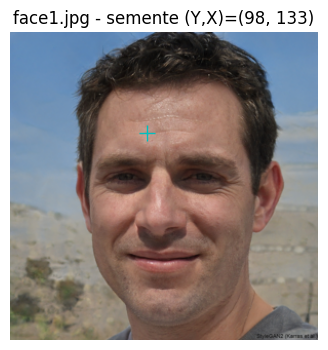

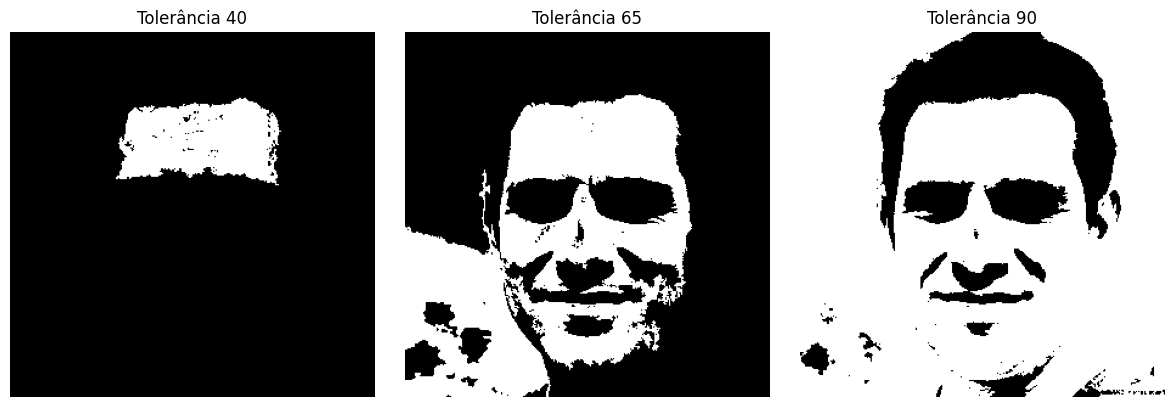

Área marcada (%): [7.8, 33.74, 78.56]


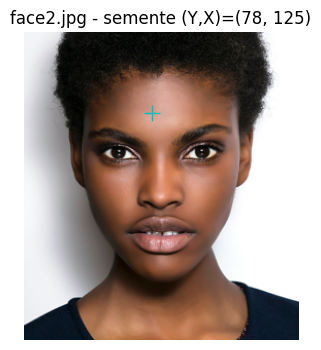

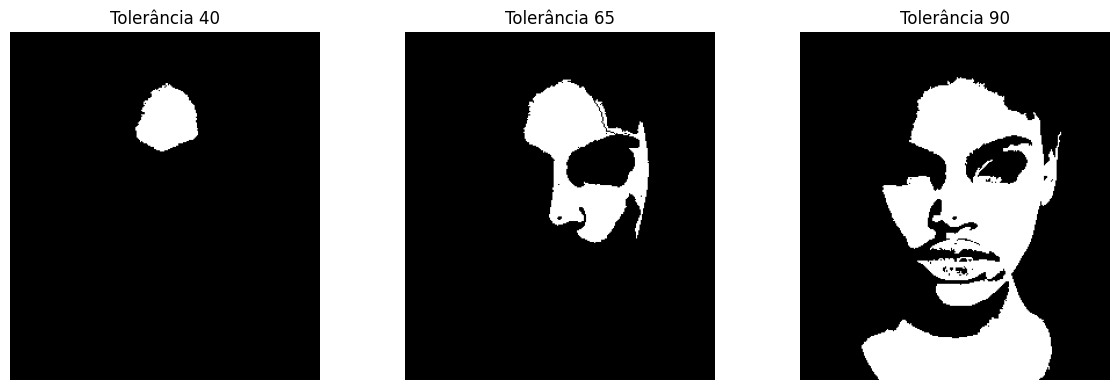

Área marcada (%): [2.74, 8.78, 28.48]


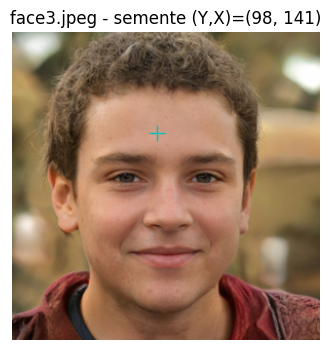

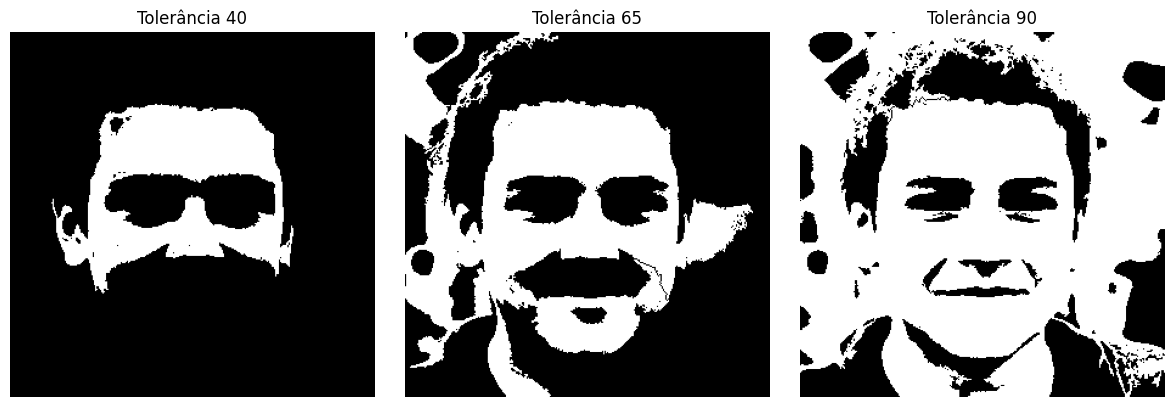

Área marcada (%): [16.22, 35.63, 70.65]


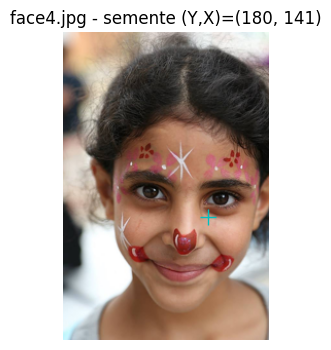

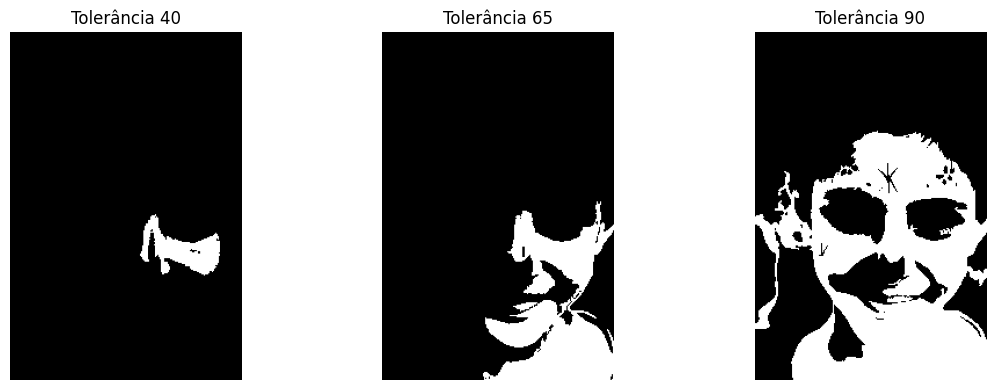

Área marcada (%): [2.75, 13.83, 37.08]


In [24]:
sementes = {
    'face1.jpg': [(98,133), (172,82)],
    'face2.jpg': [(78,125), (164,90)],
    'face3.jpeg': [(98,141), (168,109)],
    'face4.jpg': [(180,141), (188,74)]
}
areas_crescimento = []
for nome in nomes_rostos:
    imagem = abrir_imagem(nome)
    semente = sementes[nome][0]
    plt.figure(figsize=(4,4))
    plt.imshow(imagem)
    plt.plot(semente[1], semente[0], 'c+', markersize=12)
    plt.title(nome+' - semente (Y,X)='+str(semente))
    plt.axis('off')
    plt.show()
    mascaras = [crescer_regiao(imagem, semente, t) for t in [40,65,90]]
    mostrar(mascaras, ['Tolerância 40','Tolerância 65','Tolerância 90'])
    areas_crescimento.append((nome, *[100*m.mean() for m in mascaras]))
    print('Área marcada (%):', [round(float(100*m.mean()),2) for m in mascaras])

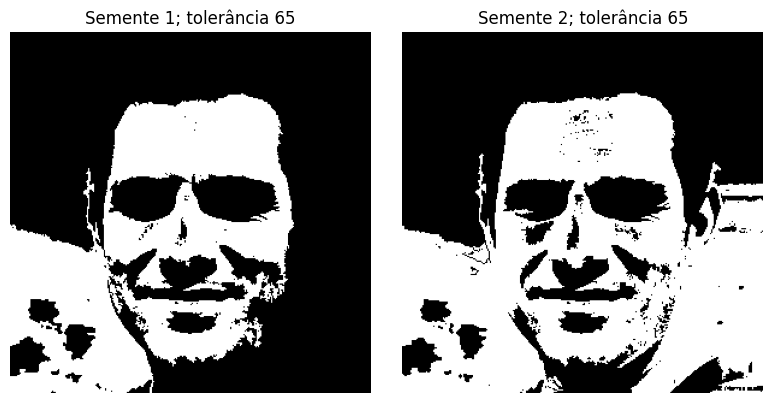

In [25]:
imagem = abrir_imagem('face1.jpg')
teste_semente = [crescer_regiao(imagem, s, 65) for s in sementes['face1.jpg']]
mostrar(teste_semente, ['Semente 1; tolerância 65', 'Semente 2; tolerância 65'])

Com tolerância pequena, a região pode parar antes de cobrir a face. Com tolerância alta, ela consegue atravessar mais variações de cor, mas pode chegar ao fundo. Trocar a semente também muda a média inicial e o caminho seguido.

Para testar outra imagem, basta carregá-la, mostrar os eixos para escolher uma coordenada dentro da pele e chamar crescer_regiao(imagem, (y,x), tolerancia).


# 6. Métricas de avaliação
IoU, Dice, precisão e recall podem avaliar esses métodos, mesmo sem Deep Learning. Para isso, precisaríamos de uma máscara correta desenhada como referência. Por exemplo, IoU divide a interseção das máscaras pela união; precisão indica quanto do que foi marcado realmente é pele ou maçã; recall indica quanto do alvo foi encontrado.


Os arquivos locais fornecidos não incluem essas máscaras. Por isso, neste trabalho comparamos visualmente os resultados e registramos a área marcada e as diferenças entre máscaras. Não tratamos essas medidas como porcentagem de acerto.

7. Imagens extras

Também testamos o agrupamento nas outras duas imagens do diretório. A transparência e os reflexos de variableObjects dificultam separar objetos do fundo apenas pela cor.

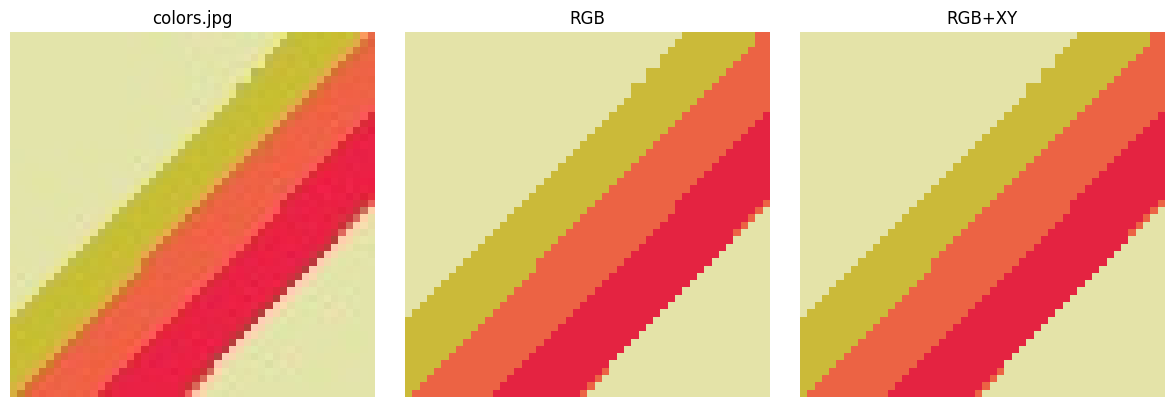

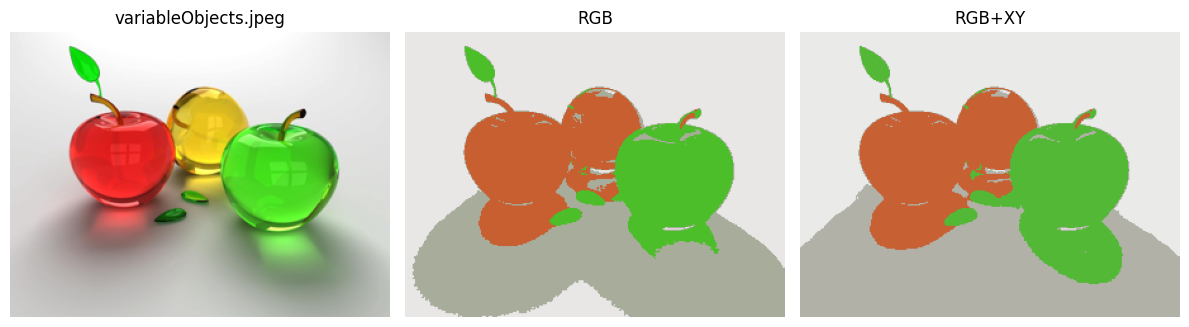

In [26]:
for nome in ['colors.jpg', 'variableObjects.jpeg']:
    imagem = abrir_imagem(nome)
    rgb = kmeans(imagem, 4)[1]
    xy = kmeans(imagem, 4, usar_xy=True)[1]
    mostrar([imagem, rgb, xy], [nome, 'RGB', 'RGB+XY'])

Concluímos que os métodos dependem da imagem e dos parâmetros. O K-means agrupa cores e posições, sem garantir um grupo por maçã; XY altera a distribuição espacial dos grupos, mas não garante contornos corretos. A morfologia remove estruturas pequenas e preenche falhas, podendo também unir frutas próximas, como em 7apples com 7x7. O HSV cobre mais regiões da face em face2, porém RGB e HSV incluem muito fundo em face3. O crescimento produz uma região conectada à semente, mas pode parar cedo ou invadir o fundo. Sem máscaras de referência, essas observações não demonstram superioridade quantitativa de um método.

Referências
Felipe Viel. Enunciado do Projeto M2 e notebook Prática - Algoritmos de Segmentação. Material da disciplina.
Imagens do GitHub da disciplina.
Kolkur et al. Human Skin Detection Using RGB, HSV and YCbCr Color Models, 2017. Artigo indicado no enunciado.
Felipe Viel. Exercise 3 — Segmentation example (exercise_3_segmentation_example.py). Material de aula consultado para comparação da implementação de crescimento de regiões.